# Lab 8: Profiling and Optimization

Part 1 profiles the Lab 1 baseline. Part 2 (at the end) optimizes it.

**Baseline:** `loop_based_mosaic` from my Lab 1 `app.py`, copied unchanged into `baseline/lab1_baseline.py`.

Dependencies are pinned in `requirements-dev.txt` and installed with `uv pip install -r requirements-dev.txt` (in place of `pip install line_profiler`).

In [1]:
%load_ext line_profiler

import cProfile
import io
import platform
import pstats
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from skimage import data

from baseline.lab1_baseline import loop_based_mosaic

Path("results").mkdir(exist_ok=True)
Path("test_images").mkdir(exist_ok=True)
print(platform.platform(), "| Python", platform.python_version(), "| numpy", np.__version__)

macOS-27.2.1-arm64-arm-64bit | Python 3.12.7 | numpy 2.5.3


## Test suite

Images: scikit-image's astronaut photo at 256, 512 and 1024 px (the 1024 is upscaled, which doesn't affect timing). Grids: 16, 32, 64. Tiles: Lab 1's 32-color synthetic palette.

In [2]:
IMAGE_SIZES, GRID_SIZES = [256, 512, 1024], [16, 32, 64]
REQUIRED = {(256, 16), (512, 32), (1024, 64)}

images = {}
for size in IMAGE_SIZES:
    path = Path(f"test_images/astronaut_{size}.png")
    if not path.exists():
        Image.fromarray(data.astronaut()).resize((size, size), Image.LANCZOS).save(path)
    images[size] = np.array(Image.open(path).convert("RGB"))

# Lab 1's tile set (same lines as in Lab 1's process_image)
num_tiles, tile_size = 32, 20
np.random.seed(42)
base_colors = np.random.randint(0, 255, size=(num_tiles, 3), dtype=np.uint8)
tile_array = np.zeros((num_tiles, tile_size, tile_size, 3), dtype=np.uint8)
for i in range(num_tiles):
    tile_array[i, :, :] = base_colors[i]
    tile_array[i, 0, :] = 20
    tile_array[i, :, 0] = 20

## Baseline timing

5 timed runs per configuration, after one untimed run.

In [3]:
def time_runs(fn, n=5):
    fn()  # untimed first run (cold caches)
    times = []
    for _ in range(n):
        start = time.perf_counter()
        fn()
        times.append(time.perf_counter() - start)
    return np.array(times)


rows = []
for size in IMAGE_SIZES:
    for grid in GRID_SIZES:
        t = time_runs(lambda: loop_based_mosaic(images[size], grid, tile_array, base_colors))
        rows.append({"image": size, "grid": grid, "cells": grid * grid,
                     "mean_s": t.mean(), "std_s": t.std(ddof=1), "min_s": t.min(),
                     "required": "✓" if (size, grid) in REQUIRED else ""})
timings = pd.DataFrame(rows)
timings.to_csv("results/baseline_timings.csv", index=False)
timings.round(4)

,image,grid,cells,mean_s,std_s,min_s,required
0,256,16,256,0.0182,0.0000,0.0182,✓
1,256,32,1024,0.0701,0.0007,0.0693,
2,256,64,4096,0.2841,0.0013,0.2821,
3,512,16,256,0.0209,0.0001,0.0208,
4,512,32,1024,0.0726,0.0006,0.0723,✓
5,512,64,4096,0.2891,0.0028,0.2862,
6,1024,16,256,0.0322,0.0001,0.0322,
7,1024,32,1024,0.0847,0.0009,0.0837,
8,1024,64,4096,0.3046,0.0010,0.3037,✓


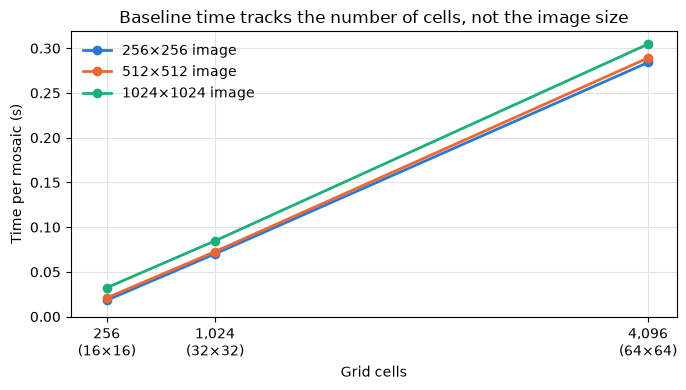

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for (size, grp), color in zip(timings.groupby("image"), ["#2a78d6", "#eb6834", "#1baf7a"]):
    ax.plot(grp.cells, grp.mean_s, marker="o", lw=2, color=color, label=f"{size}×{size} image")
ax.set(xlim=(0, 4300), ylim=(0, None), xlabel="Grid cells", ylabel="Time per mosaic (s)",
       title="Baseline time tracks the number of cells, not the image size")
ax.set_xticks([256, 1024, 4096], ["256\n(16×16)", "1,024\n(32×32)", "4,096\n(64×64)"])
ax.grid(color="#e4e3de")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("results/baseline_scaling.png", dpi=200)
plt.show()

Time grows almost linearly with the number of cells. Image size matters much less: a 16× larger image costs 7% more at the 64×64 grid and 77% more at 16×16, where each cell holds more pixels to average. So most of the cost is per-cell Python overhead, not pixel math. 512×512 / 32×32 takes about 0.073 s, so 20× means getting it down to about 3.6 ms.

## cProfile (512×512, 32×32)

In [5]:
def profile(fn, *args, top=10):
    prof = cProfile.Profile()
    prof.runcall(fn, *args)
    stream = io.StringIO()
    pstats.Stats(prof, stream=stream).strip_dirs().sort_stats("tottime").print_stats(top)
    print(stream.getvalue())


img512 = images[512]
profile(loop_based_mosaic, img512, 32, tile_array, base_colors)

         273793 function calls (273792 primitive calls) in 0.144 seconds

   Ordered by: internal time
   List reduced from 78 to 10 due to restriction <10>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.047    0.047    0.143    0.143 lab1_baseline.py:30(loop_based_mosaic)
    32768    0.039    0.000    0.081    0.000 _linalg.py:2598(norm)
    32768    0.021    0.000    0.021    0.000 {method 'dot' of 'numpy.ndarray' objects}
    32768    0.007    0.000    0.007    0.000 {method 'ravel' of 'numpy.ndarray' objects}
     1024    0.007    0.000    0.007    0.000 {method 'reduce' of 'numpy.ufunc' objects}
    66560    0.006    0.000    0.006    0.000 {built-in method builtins.issubclass}
    32768    0.005    0.000    0.008    0.000 _linalg.py:168(isComplexType)
    32768    0.003    0.000    0.003    0.000 {built-in method numpy.asarray}
     1024    0.003    0.000    0.012    0.000 _methods.py:115(_mean)
    32768    0.003    0.000    0.003    0.0

`np.linalg.norm` (listed as `_linalg.py:2598(norm)`, the NumPy file it's defined in) is called 32,768 times (1,024 cells × 32 tiles) and takes over half the run, almost all of it call overhead on 3-element vectors. `np.mean` is called once per cell. There's no file I/O.

## line_profiler: `loop_based_mosaic` (512×512, 32×32)

`%lprun` output goes to Jupyter's pager, which isn't saved in the notebook, so `-T` writes it to a file that's printed below.

In [6]:
%lprun -u 1e-3 -T results/lprun_loop_based_mosaic.txt -f loop_based_mosaic loop_based_mosaic(img512, 32, tile_array, base_colors)
print(Path("results/lprun_loop_based_mosaic.txt").read_text())


*** Profile printout saved to text file 'results/lprun_loop_based_mosaic.txt'.
Timer unit: 0.001 s

Total time: 0.345514 s
File: /Users/robertwzhou/Documents/GitHub/ImageMosaicGenerator/baseline/lab1_baseline.py
Function: loop_based_mosaic at line 30

Line #      Hits         Time  Per Hit   % Time  Line Contents
    30                                           def loop_based_mosaic(img_array, grid_size, tile_array, base_colors):
    31         1          0.0      0.0      0.0      height, width, channels = img_array.shape
    32         1          0.0      0.0      0.0      tile_h, tile_w = height // grid_size, width // grid_size
    33         1          0.0      0.0      0.0      display_tile_size = tile_array.shape[1]
    34                                               
    35         1          0.0      0.0      0.0      final_img = np.zeros((grid_size * display_tile_size, grid_size * display_tile_size, 3), dtype=np.uint8)
    36                                               
  

Line 48, `dist = np.linalg.norm(avg_color - color)` in the inner tile loop, takes about 87% of the function. The per-cell `np.mean` (line 43) is about 6%. Line numbers are the same as in the Lab 1 version of `app.py`.

## Bottlenecks to fix in Part 2

| # | Bottleneck | Evidence | Fix |
|---|---|---|---|
| 1 | One `np.linalg.norm` call per cell per tile (line 48) | 32,768 calls, ~87% of function time | Compute all cell-to-tile distances in one operation, then `argmin` |
| 2 | Python loop over cells with a separate `np.mean` each (lines 37–43) | 1,024 iterations, ~6% in `np.mean` alone | Average all cells in one operation |
| 3 | Tile pasted one cell at a time (line 55) | 1,024 slice assignments | Index `tile_array` with the chosen-tile grid, then reshape |
| 4 | Redundant work per request | Lab 1's handler runs this loop only to report its time, and rebuilds the tile set each request | Run only the fast path; build the tile set once and cache it |

## Part 2: Optimization

The optimized code is in `app.py`, one function per stage:
- **Cell averages** (`cell_averages`): one box-filter downscale with PIL's `Image.reduce`, instead of 1,024 `np.mean` calls.
- **Tile matching** (`match_tiles`): every cell against every tile in one matrix product, then `argmin`.
- **Assembly** (`assemble`): index the tile array with the grid of chosen tiles and reshape, instead of 1,024 pastes.
- **Caching and redundant work:** the tile set is built once per palette size (`lru_cache`), and the app no longer runs the loop version on every request.

The baseline times below come from Part 1, earlier in this same run, so both versions were measured under the same conditions.

In [7]:
from app import assemble, build_tiles, cell_averages, match_tiles, optimized_mosaic, process_image

opt_ms = [1e3 * time_runs(lambda: optimized_mosaic(images[size], grid, tile_array, base_colors), n=50).mean()
          for size, grid in zip(timings.image, timings.grid)]
comparison = timings[["image", "grid", "required"]].assign(baseline_ms=1e3 * timings.mean_s, optimized_ms=opt_ms)
comparison["speedup"] = comparison.baseline_ms / comparison.optimized_ms
comparison.to_csv("results/optimized_timings.csv", index=False)
comparison.round(2)

,image,grid,required,baseline_ms,optimized_ms,speedup
0,256,16,✓,18.22,0.23,80.53
1,256,32,,70.07,0.53,131.42
2,256,64,,284.08,1.70,166.88
3,512,16,,20.90,0.51,40.86
4,512,32,✓,72.59,0.79,91.62
5,512,64,,289.10,1.99,145.39
6,1024,16,,32.24,1.61,20.09
7,1024,32,,84.66,1.90,44.66
8,1024,64,✓,304.58,3.10,98.27


At 512×512 / 32×32 the optimized version takes 0.79 ms against 73 ms, a **92× speedup** (the target is 20×; 50–100× is the aim). The three required configurations are 81–98× faster. The smallest gain is 20×, at 1024×1024 / 16×16: with only 256 cells, the baseline has little loop overhead to remove, while the optimized version still has to read every one of the million pixels.

### Speedup from each optimization (512×512, 32×32)

Each optimized step, timed against a loop version of the same step. The loop versions are Lab 1's loop split into one loop per step, which adds some overhead, so their times run a little high (the check printed below compares their total with the real loop).

In [8]:
img, g = images[512], 32
c = 512 // g


def loop_averages():  # Lab 1 lines 37-43, as their own loop
    avg = np.zeros((g, g, 3))
    for r in range(g):
        for k in range(g):
            avg[r, k] = np.mean(img[r*c:(r+1)*c, k*c:(k+1)*c], axis=(0, 1))
    return avg


def loop_match():  # Lab 1 lines 45-51, as their own loop
    best = np.zeros((g, g), dtype=int)
    for r in range(g):
        for k in range(g):
            min_dist = float('inf')
            for i, color in enumerate(base_colors):
                dist = np.linalg.norm(avg[r, k] - color)
                if dist < min_dist:
                    min_dist, best[r, k] = dist, i
    return best


def loop_paste():  # Lab 1 lines 53-55, as their own loop
    out = np.zeros((g * 20, g * 20, 3), dtype=np.uint8)
    for r in range(g):
        for k in range(g):
            out[r*20:(r+1)*20, k*20:(k+1)*20] = tile_array[best[r, k]]
    return out


avg = loop_averages()  # inputs for the later steps
best = loop_match()
reduced = cell_averages(img, g)[1]
stages = {
    "Cell averages": (loop_averages, lambda: cell_averages(img, g)),
    "Tile matching": (loop_match, lambda: match_tiles(reduced, base_colors)),
    "Assembly": (loop_paste, lambda: assemble(best, tile_array)),
    "Tile set (rebuilt vs cached)": (lambda: build_tiles.__wrapped__(32), lambda: build_tiles(32)),
}
rows = []
for name, (without, with_) in stages.items():
    without_ms, with_ms = 1e3 * time_runs(without).mean(), 1e3 * time_runs(with_, n=50).mean()
    rows.append({"optimization": name, "without_ms": without_ms, "with_ms": with_ms, "speedup": without_ms / with_ms})
per_step = pd.DataFrame(rows)
loops_total = per_step.without_ms[:3].sum()
real_loop = 1e3 * timings.set_index(["image", "grid"]).loc[(512, 32), "mean_s"]
print(f"Check: the three loop versions add up to {loops_total:.0f} ms; the real loop takes {real_loop:.0f} ms.")
per_step.round(3)

Check: the three loop versions add up to 78 ms; the real loop takes 73 ms.


,optimization,without_ms,with_ms,speedup
0,Cell averages,8.566,0.386,22.196
1,Tile matching,68.283,0.059,1153.910
2,Assembly,1.022,0.338,3.024
3,Tile set (rebuilt vs cached),0.161,0.000,1184.709


Tile matching gained the most, over 1,000×: 32,768 `norm` calls became one matrix product. Cell averages are about 22× faster and assembly about 3×. Caching the tile set saves only 0.16 ms per request, because Lab 1's tiles are generated in memory. Removing the discarded loop run from the app means each request no longer pays the full baseline time on top of the mosaic.

### Correctness check

Percentage of cells where the optimized mosaic uses the same tile as the baseline, and the MSE between the two mosaics.

In [9]:
def same_tile_pct(a, b, g, ts=20):
    a, b = a.reshape(g, ts, g, ts, 3), b.reshape(g, ts, g, ts, 3)
    return 100 * (a == b).all(axis=(1, 3, 4)).mean()


rows = []
for size, grid in sorted(REQUIRED):
    base = loop_based_mosaic(images[size], grid, tile_array, base_colors)
    opt = optimized_mosaic(images[size], grid, tile_array, base_colors)[0]
    rows.append({"image": size, "grid": grid, "same_tile_pct": same_tile_pct(base, opt, grid),
                 "mse": np.mean((base.astype(float) - opt) ** 2)})
pd.DataFrame(rows).round(1)

,image,grid,same_tile_pct,mse
0,256,16,98.0,24.3
1,512,32,99.1,11.1
2,1024,64,99.3,12.0


98–99% of cells get the same tile as the baseline. The MSE between the two mosaics (11–24, with pixel values from 0 to 255) comes entirely from the cells that differ.

### cProfile of the optimized version (512×512, 32×32)

One call takes under a millisecond, too short to profile reliably, so this profiles 100 calls.

In [10]:
profile(lambda: [optimized_mosaic(img512, 32, tile_array, base_colors) for _ in range(100)])

         12384 function calls (12383 primitive calls) in 0.108 seconds

   Ordered by: internal time
   List reduced from 112 to 10 due to restriction <10>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      300    0.042    0.000    0.042    0.000 {method 'reshape' of 'numpy.ndarray' objects}
      100    0.019    0.000    0.019    0.000 {method 'reduce' of 'ImagingCore' objects}
      100    0.018    0.000    0.018    0.000 {method 'decode' of 'ImagingDecoder' objects}
      100    0.008    0.000    0.050    0.000 app.py:45(assemble)
      100    0.005    0.000    0.005    0.000 {built-in method PIL._imaging.fill}
      100    0.004    0.000    0.008    0.000 app.py:35(match_tiles)
      100    0.003    0.000    0.003    0.000 {method 'argmin' of 'numpy.ndarray' objects}
      100    0.001    0.000    0.002    0.000 Image.py:842(tobytes)
      100    0.001    0.000    0.026    0.000 Image.py:3378(fromarray)
      100    0.000    0.000    0.025    0.000 Image

Assembly is now the biggest cost, about half the time. Most of it is the `reshape` that copies the chosen tiles into the 640×640 output. Next come handing the image to PIL (`decode`) and the box filter (`reduce`); matching is under 10%. What's left is mostly copying pixels, so there isn't much more to gain.